# HEALPix (raw / compressed) versus the UTM source — T31UDQ, 13 June 2025

Product: `S2C_MSIL2A_20250613T104641_N0511_R051_T31UDQ_20250613T134507`, 10 m bands (B02, B03, B04, B08).

Datasets compared:

| Name | Location | Content |
|---|---|---|
| **UTM** | L2A source tile (EOPF, or its grid4earth mirror) | `uint16` digital numbers on the UTM 31N 10 m grid, converted here to reflectance |
| **HEALPix raw** | `s3://grid4earth/test-compression/<product>/r10m/healpix_raw.zarr` | reflectance at level 20 (nested, WGS84), zstd only |
| **HEALPix compressed** | `.../healpix_codec.zarr` | same field, `hcc-sentinel2-pyramid` codec |

All values in this notebook are **surface reflectance** (dimensionless). The L2A digital numbers are converted with
`reflectance = DN × 1e-4 − 0.1` (the product's `scale_factor` and `add_offset`). An error of 0.001 in reflectance equals 10 DN.

Outline:
1. Find the UTM tile of the right date (EOPF STAC catalogue, otherwise the mirror).
2. **Visual check**: 4 patches of 512×512 UTM pixels, with the raw and compressed HEALPix values shown on the same grid (the cell that contains each pixel centre, no interpolation).
3. **HEALPix → UTM reprojection** with `healpix_resample.PSFResampler` (same parameters as the conversion), then the residuals `UTM − PSF(HEALPix)` for the raw and the compressed fields.
4. **Radial power spectra** of these residuals.

Run with the **Python (venv-hc)** kernel under WSL (s3fs, zarr 3, torch, `healpix_resample`, `hcc` from `healpix-compress-s2`), AWS profile `default`, OVH GRA endpoint.

In [1]:
import sys, json, time, logging, functools
from concurrent.futures import ThreadPoolExecutor

# The healpix-compress repo has its own `hcc/` folder: make sure we import the
# healpix-compress-s2 package (which provides the hcc-sentinel2-pyramid codec).
sys.path = [p for p in sys.path if not p.rstrip("/").endswith("healpix-compress")]
import hcc
assert "healpix-compress-s2" in hcc.__file__, hcc.__file__

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
import pyproj, s3fs, torch, zarr, zarr.storage
from zarr.registry import register_codec
from hcc.codecs.sentinel2_pyramid import HccSentinel2PyramidCodec
from healpix_geo.nested import lonlat_to_healpix
from healpix_resample.psf import PSFResampler

register_codec("hcc-sentinel2-pyramid", HccSentinel2PyramidCodec)
logging.getLogger("asyncio").setLevel(logging.CRITICAL)
import warnings; warnings.filterwarnings("ignore", category=UserWarning, module="healpix_resample")
torch.set_num_threads(16)
plt.rcParams.update({"figure.dpi": 72, "image.interpolation": "nearest"})   # 72 dpi keeps the notebook small enough for GitHub

PID = "S2C_MSIL2A_20250613T104641_N0511_R051_T31UDQ_20250613T134507"
HPX = f"grid4earth/test-compression/{PID}/r10m"
BANDS = ["b02", "b03", "b04", "b08"]
N, MARGIN, DX = 512, 8, 10.0            # patch size (px), extra pixels for the cell search, pixel size (m)
EP = dict(profile="default", endpoint_url="https://s3.gra.io.cloud.ovh.net", client_kwargs={"region_name": "gra"})
fs = s3fs.S3FileSystem(**EP)
afs = s3fs.S3FileSystem(asynchronous=True, **EP)
open_group = lambda p: zarr.open_group(zarr.storage.FsspecStore(afs, path=p, read_only=True), mode="r")
print("torch", torch.__version__, "| cuda:", torch.cuda.is_available())

torch 2.14.1+cpu | cuda: False


## 1. UTM reference tile

The product is first searched in the EOPF STAC catalogue (`https://stac.core.eopf.eodc.eu`), by identifier, then by MGRS tile and date. The EOPF catalogue is a curated view whose holdings change: products are withdrawn over time. If the product is no longer listed, the grid4earth mirror is read instead. That mirror is exactly the input read by the conversion (`_location` field of `source.json`).

In [2]:
import pystac_client

source = json.loads(fs.cat(f"{HPX}/source.json"))
mirror = source["_location"].removeprefix("s3://")
print("conversion input (source.json):", source["_location"])

utm_href = None
try:
    cat = pystac_client.Client.open("https://stac.core.eopf.eodc.eu")
    by_id = list(cat.search(collections=["sentinel-2-l2a"], ids=[PID]).items())
    same_day = list(cat.search(collections=["sentinel-2-l2a"], bbox=[2.36, 49.15, 2.38, 49.17],
                               datetime="2025-06-13").items())
    print(f"EOPF STAC: by id -> {len(by_id)} item(s); T31UDQ on 2025-06-13 -> {len(same_day)} item(s)")
    for it in by_id + same_day:
        print("   ", it.id, it.assets["product"].href if "product" in it.assets else "")
    if by_id:
        utm_href = by_id[0].assets["product"].href
    june = sorted(cat.search(collections=["sentinel-2-l2a"], bbox=[2.36, 49.15, 2.38, 49.17],
                             datetime="2025-06-01/2025-06-30").items(), key=lambda i: i.properties["datetime"])
    print("T31UDQ items in June 2025 still listed by EOPF:", [i.id[:27] for i in june])
except Exception as e:
    print("EOPF STAC query failed:", e)

if utm_href:
    print("-> UTM read from EOPF:", utm_href)
    utm = zarr.open_group(zarr.storage.FsspecStore.from_url(utm_href + "/measurements/reflectance/r10m",
                                                            read_only=True), mode="r")
else:
    print("-> product no longer in the EOPF STAC: UTM read from the grid4earth mirror (identical to the conversion input)")
    utm = open_group(f"{mirror}/measurements/reflectance/r10m")

x_utm, y_utm = utm["x"][:], utm["y"][:]          # pixel centres, EPSG:32631
A = utm["b04"].attrs
SCALE, OFFSET = float(A["scale_factor"]), float(A["add_offset"])
print(f"DN -> reflectance: refl = DN * {SCALE:g} {OFFSET:+g}   (DN fill value {A['fill_value']})")
print("x:", x_utm[0], "..", x_utm[-1], " y:", y_utm[0], "..", y_utm[-1])

conversion input (source.json): s3://grid4earth/public/eopf-mirror/sentinel-2-l2a/S2C_MSIL2A_20250613T104641_N0511_R051_T31UDQ_20250613T134507.zarr


EOPF STAC: by id -> 0 item(s); T31UDQ on 2025-06-13 -> 0 item(s)
T31UDQ items in June 2025 still listed by EOPF: ['S2B_MSIL2A_20250601T105619_', 'S2B_MSIL2A_20250608T104619_', 'S2A_MSIL2A_20250608T105711_']
-> product no longer in the EOPF STAC: UTM read from the grid4earth mirror (identical to the conversion input)


DN -> reflectance: refl = DN * 0.0001 -0.1   (DN fill value 0)
x: 399965.0 .. 509755.0  y: 5.500015e+06 .. 5.390225e+06


## 2. HEALPix stores and conversion parameters

Summary written by the conversion (`sizes.json`). The compression error of the codec is given here over the whole tile, in reflectance.

In [3]:
sizes = json.loads(fs.cat(f"{HPX}/sizes.json"))
RES = sizes["resampler"]
print("resampler used by the conversion:", RES)
print("codec:", sizes["codec"])
print(f"\n{'band':5}{'cells':>12}{'bits/cell':>11}{'UTM JXL bits/px':>17}{'codec RMS err':>15}{'codec max err':>15}")
for b in BANDS:
    s = sizes["bands"][b]
    print(f"{b:5}{s['healpix']['cells']:>12}{s['ratios']['hcc-sentinel2-pyramid_bits_per_cell']:>11.3f}"
          f"{s['ratios']['utm_bits_per_pixel']['jpegxl_lossless']:>17.3f}"
          f"{s['healpix_raw']['rms_err_in_range_dn'] * SCALE:>15.5f}{s['healpix_raw']['max_abs_err_in_range']:>15.5f}")
print("(errors in reflectance units)")

raw = open_group(f"{HPX}/healpix_raw.zarr/measurements/reflectance/20")
cod = open_group(f"{HPX}/healpix_codec.zarr/measurements/reflectance/20")
cid = raw["cell_ids"]
CS, NCH = cid.chunks[0], cid.nchunks
print(f"\n{cid.shape[0]:,} cells in {NCH} chunks of {CS} (one level-11 parent cell per chunk, sorted)")

resampler used by the conversion: {'init_params': {'Npt': 9, 'threshold': 0.1}, 'resample_params': {'lam': 0.1, 'max_iter': 100, 'tol': 1e-08}}
codec: {'name': 'hcc-sentinel2-pyramid', 'configuration': {'quantification_value': 10000.0, 'add_offset': -1000.0}}

band        cells  bits/cell  UTM JXL bits/px  codec RMS err  codec max err
b02     334757888      3.744            7.616        0.00089        0.00578
b03     334757888      3.950            7.767        0.00097        0.00609
b04     334757888      3.765            7.718        0.00102        0.00570
b08     334757888      4.354            9.492        0.00206        0.00641
(errors in reflectance units)



334,757,888 cells in 1277 chunks of 262144 (one level-11 parent cell per chunk, sorted)


## 3. Patch extraction

Each HEALPix chunk holds exactly one level-11 parent cell, and the chunks are sorted. The chunks needed for a patch are therefore found by a binary search on their parent cell, without reading the whole index. For each patch, all the level-11 parent cells touching the patch (enlarged by a few pixels) are loaded, so that the PSF kernel has its neighbours at the patch edge.

In [4]:
to_wgs = pyproj.Transformer.from_crs(32631, 4326, always_xy=True)
to_utm = pyproj.Transformer.from_crs(4326, 32631, always_xy=True)

@functools.lru_cache(None)
def chunk_parent(i):
    return int(cid[i * CS] >> np.uint64(18))

def find_chunk(parent):
    lo, hi = 0, NCH - 1
    while lo <= hi:
        mid = (lo + hi) // 2
        p = chunk_parent(mid)
        if p == parent:
            return mid
        lo, hi = (mid + 1, hi) if p < parent else (lo, mid - 1)
    return None

def read_chunks(arr, chunks):
    with ThreadPoolExecutor(16) as ex:
        return np.concatenate(list(ex.map(lambda c: arr[c * CS:(c + 1) * CS], chunks)))

def load_patch(name, lon0, lat0):
    t = time.time()
    xc, yc = to_utm.transform(lon0, lat0)
    j0 = int(round((xc - x_utm[0]) / DX)) - N // 2
    i0 = int(round((y_utm[0] - yc) / DX)) - N // 2
    with ThreadPoolExecutor(4) as ex:
        dn = np.stack(list(ex.map(lambda b: utm[b][i0:i0 + N, j0:j0 + N], BANDS))).astype(float)
    refl = np.where(dn == 0, np.nan, dn * SCALE + OFFSET)          # DN 0 = L2A fill value
    XX, YY = np.meshgrid(x_utm[j0 - MARGIN:j0 + N + MARGIN], y_utm[i0 - MARGIN:i0 + N + MARGIN])
    LON, LAT = to_wgs.transform(XX, YY)
    parents = np.unique(np.asarray(lonlat_to_healpix(LON.ravel(), LAT.ravel(), 11, ellipsoid="WGS84")))
    chunks = [c for c in (find_chunk(int(p)) for p in parents) if c is not None]
    cells = read_chunks(cid, chunks)
    hpx = {k: np.stack([read_chunks(g[b], chunks) for b in BANDS]) for k, g in (("raw", raw), ("codec", cod))}
    o = np.argsort(cells)
    lon, lat = LON[MARGIN:-MARGIN, MARGIN:-MARGIN], LAT[MARGIN:-MARGIN, MARGIN:-MARGIN]
    # cell containing each UTM pixel centre (no interpolation)
    nc = np.asarray(lonlat_to_healpix(lon.ravel(), lat.ravel(), 20, ellipsoid="WGS84")).astype(np.uint64)
    pn = np.searchsorted(cells[o], nc)
    assert np.all(cells[o][np.minimum(pn, cells.size - 1)] == nc), "missing cells"
    P = dict(name=name, lon0=lon0, lat0=lat0, i0=i0, j0=j0, utm=refl, lon=lon, lat=lat,
             cells=cells[o], hpx={k: v[:, o] for k, v in hpx.items()})
    P["nearest"] = {k: v[:, pn].reshape(len(BANDS), N, N) for k, v in P["hpx"].items()}
    print(f"{name:28s} {len(parents)} parent cells, {cells.size:,} cells, "
          f"{np.isnan(refl).mean() * 100:.2f}% UTM fill, {time.time() - t:.1f}s")
    return P

SITES = {   # (lon, lat) of the patch centre, all inside T31UDQ
    "Paris centre (urban)":     (2.3470, 48.8540),
    "Roissy-CDG (airport)":     (2.5500, 49.0097),
    "Compiegne forest":         (2.8800, 49.3700),
    "Vexin (agriculture)":      (1.8500, 49.1500),
}
patches = [load_patch(k, *v) for k, v in SITES.items()]

Paris centre (urban)         7 parent cells, 1,835,008 cells, 0.00% UTM fill, 13.9s


Roissy-CDG (airport)         7 parent cells, 1,835,008 cells, 0.00% UTM fill, 13.9s


Compiegne forest             7 parent cells, 1,835,008 cells, 0.00% UTM fill, 13.6s


Vexin (agriculture)          7 parent cells, 1,835,008 cells, 0.00% UTM fill, 16.9s


## 4. Visual check

For each patch: B04/B03/B02 colour composite in UTM, then raw and compressed HEALPix (value of the cell that contains each pixel centre), all with the same contrast stretch. The first colour bar gives that stretch in reflectance (the same range is applied to each of the R, G and B channels). The last column shows the compressed − raw difference on B04, also in reflectance, so that both colour bars can be compared directly. The second row of each patch zooms on the central 128×128 pixels.

The "cell containing the pixel" view samples cells of about 6 m at one point. It is therefore noisier than the UTM image, which integrates over 10 m: this is expected and is not a codec effect.

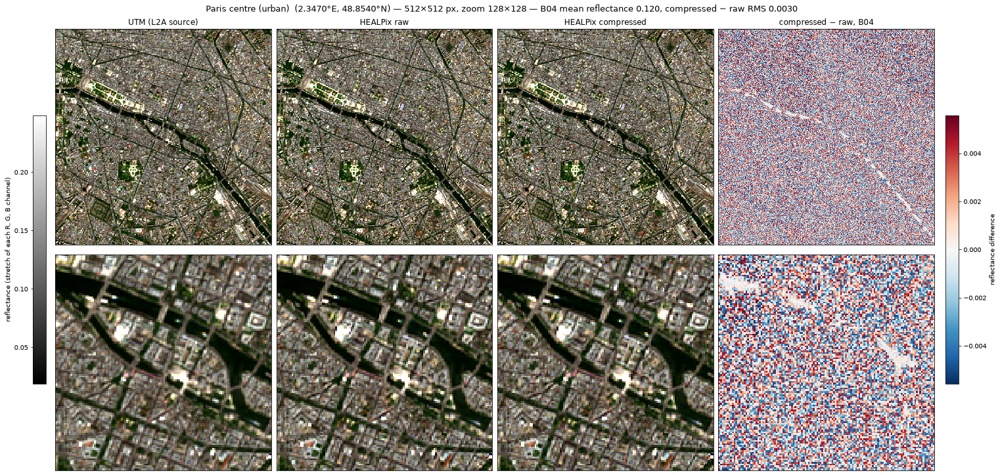

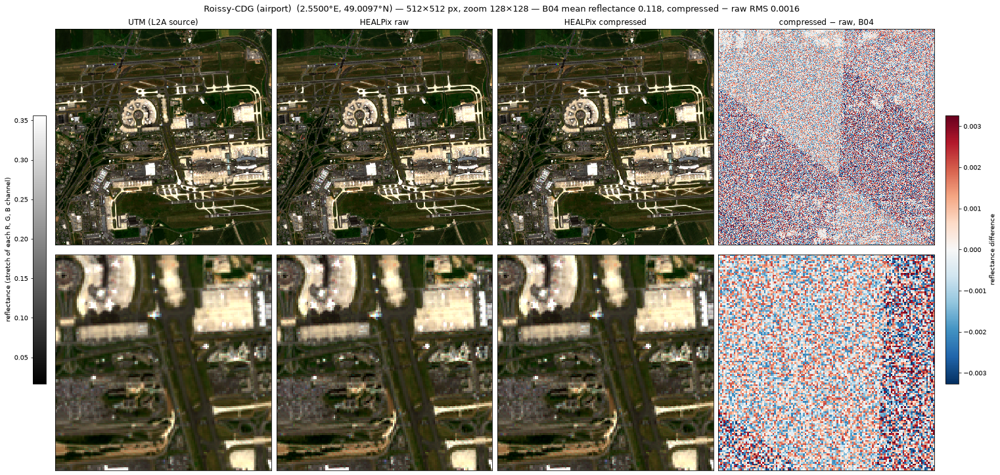

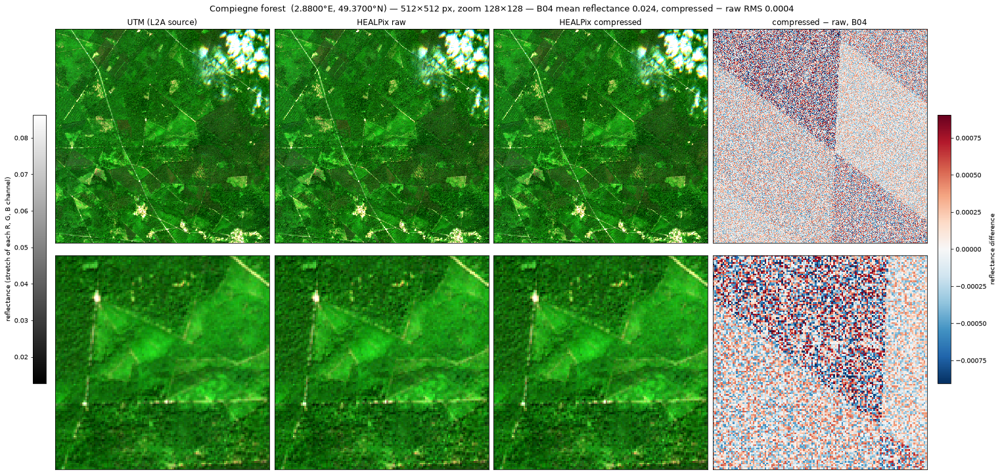

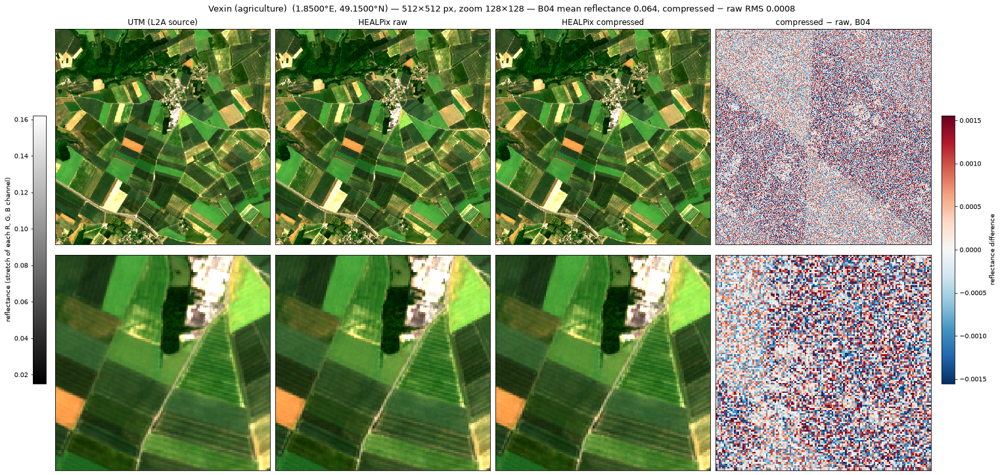

In [5]:
def rgb(stack, lo, hi):
    return np.clip((np.dstack([stack[2], stack[1], stack[0]]) - lo) / (hi - lo), 0, 1)

Z = slice(N // 2 - 64, N // 2 + 64)
for P in patches:
    lo, hi = np.nanpercentile(P["utm"][:3], [2, 98])
    d = P["nearest"]["codec"][2] - P["nearest"]["raw"][2]
    lim = np.percentile(np.abs(d), 99.5)
    fig, ax = plt.subplots(2, 4, figsize=(21, 10), constrained_layout=True)
    for row, sl in enumerate([(slice(None), slice(None)), (Z, Z)]):
        ax[row, 0].imshow(rgb(P["utm"][:, sl[0], sl[1]], lo, hi))
        ax[row, 1].imshow(rgb(P["nearest"]["raw"][:, sl[0], sl[1]], lo, hi))
        ax[row, 2].imshow(rgb(P["nearest"]["codec"][:, sl[0], sl[1]], lo, hi))
        im = ax[row, 3].imshow(d[sl], cmap="RdBu_r", vmin=-lim, vmax=lim)
    fig.colorbar(ScalarMappable(Normalize(lo, hi), "gray"), ax=ax[:, :3], shrink=0.6, location="left", pad=0.01,
                 label="reflectance (stretch of each R, G, B channel)")
    fig.colorbar(im, ax=ax[:, 3], shrink=0.6, label="reflectance difference")
    for a, t in zip(ax[0], ["UTM (L2A source)", "HEALPix raw", "HEALPix compressed", "compressed − raw, B04"]):
        a.set_title(t)
    for a in ax.flat:
        a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"{P['name']}  ({P['lon0']:.4f}°E, {P['lat0']:.4f}°N) — 512×512 px, zoom 128×128 — "
                 f"B04 mean reflectance {np.nanmean(P['utm'][2]):.3f}, compressed − raw RMS {np.sqrt(np.mean(d ** 2)):.4f}",
                 fontsize=13)
    plt.show()

## 5. HEALPix → UTM reprojection with `PSFResampler`

The conversion's `PSFResampler` models each UTM pixel as a Gaussian-weighted average of its `Npt` nearest HEALPix cells. The conversion solves this model in the least-squares sense to obtain the cells. The reverse operation, `invert`, applies the same model to the cells, and therefore predicts the UTM pixels.

The resampler is built on the patch pixel centres, with the same `Npt` and `threshold` as the conversion. The raw and compressed fields are then reprojected. The residuals are:

- `UTM − PSF(raw)`: error of the UTM → HEALPix → UTM round trip alone;
- `UTM − PSF(compressed)`: the same, plus the codec error;
- `PSF(compressed) − PSF(raw)`: the codec error alone, seen on the UTM grid.

The table gives RMS values in units of 10⁻³ reflectance (1 unit = 10 DN), next to the mean and standard deviation of the UTM signal in the same units.

In [6]:
for P in patches:
    t = time.time()
    R = PSFResampler(P["lon"].ravel(), P["lat"].ravel(), level=20, device="cpu", dtype=torch.float64,
                     verbose=False, **RES["init_params"])
    rc = R.cell_ids.cpu().numpy().astype(np.uint64)
    pos = np.searchsorted(P["cells"], rc)
    assert np.all(P["cells"][np.minimum(pos, P["cells"].size - 1)] == rc), "resampler needs cells not loaded"
    P["psf"] = {k: R.invert(v[:, pos]).reshape(len(BANDS), N, N) for k, v in P["hpx"].items()}
    # codec error in the HEALPix domain, on the cells used by this patch
    P["hpx_err"] = P["hpx"]["codec"][:, pos] - P["hpx"]["raw"][:, pos]
    print(f"{P['name']:28s} K={R.K:,} cells, {time.time() - t:.1f}s")
    del R

def rms(a, axis=(1, 2)):
    return np.sqrt(np.nanmean(a ** 2, axis=axis))

print(f"\nunits: 1e-3 reflectance{'':10s}" + "".join(f"{b:>9}" for b in BANDS))
for P in patches:
    lines = {
        "UTM signal mean":              np.nanmean(P["utm"], axis=(1, 2)),
        "UTM signal std":               np.nanstd(P["utm"], axis=(1, 2)),
        "RMS UTM − PSF(raw)":           rms(P["utm"] - P["psf"]["raw"]),
        "RMS UTM − PSF(compressed)":    rms(P["utm"] - P["psf"]["codec"]),
        "RMS PSF(compr.) − PSF(raw)":   rms(P["psf"]["codec"] - P["psf"]["raw"]),
        "RMS compr. − raw (HEALPix)":   rms(P["hpx_err"], axis=1),
    }
    print(P["name"])
    for k, v in lines.items():
        print(f"   {k:30s}" + "".join(f"{x * 1e3:9.2f}" for x in v))

Paris centre (urban)         K=679,273 cells, 2.1s


Roissy-CDG (airport)         K=679,286 cells, 1.4s


Compiegne forest             K=679,371 cells, 1.4s


Vexin (agriculture)          K=679,196 cells, 1.7s

units: 1e-3 reflectance                b02      b03      b04      b08
Paris centre (urban)
   UTM signal mean                   97.58   116.32   120.02   194.85
   UTM signal std                    60.56    59.38    63.88    97.68
   RMS UTM − PSF(raw)                 1.12     1.12     1.10     1.22
   RMS UTM − PSF(compressed)          2.01     2.06     2.03     2.25
   RMS PSF(compr.) − PSF(raw)         1.67     1.73     1.70     1.89
   RMS compr. − raw (HEALPix)         2.97     3.07     3.03     3.36
Roissy-CDG (airport)
   UTM signal mean                   83.41   116.80   117.77   296.19
   UTM signal std                    78.81    79.53    90.18   110.09
   RMS UTM − PSF(raw)                 0.58     0.60     0.60     0.84
   RMS UTM − PSF(compressed)          1.05     1.09     1.10     1.57
   RMS PSF(compr.) − PSF(raw)         0.87     0.90     0.92     1.33
   RMS compr. − raw (HEALPix)         1.51     1.58     1.61     2

Residual maps for B04. The left panel shows the UTM data with its own colour bar; the three residual panels share one colour bar, in the same reflectance units, so the residual level can be read against the data level.

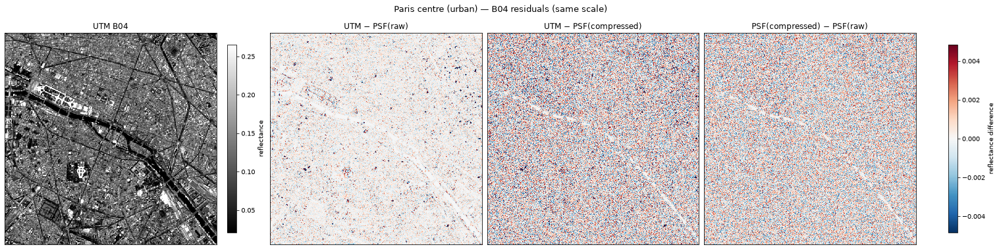

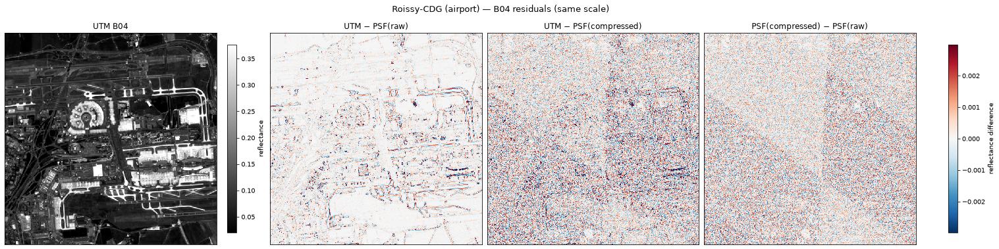

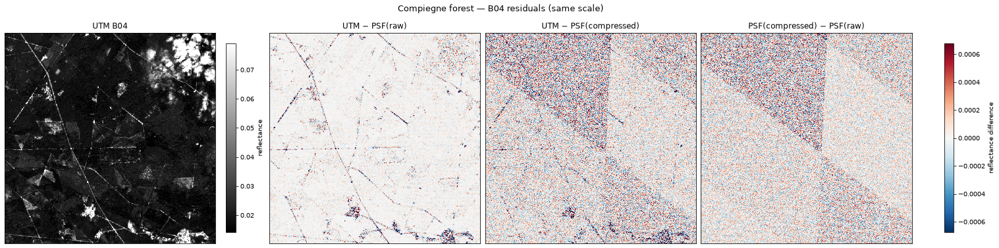

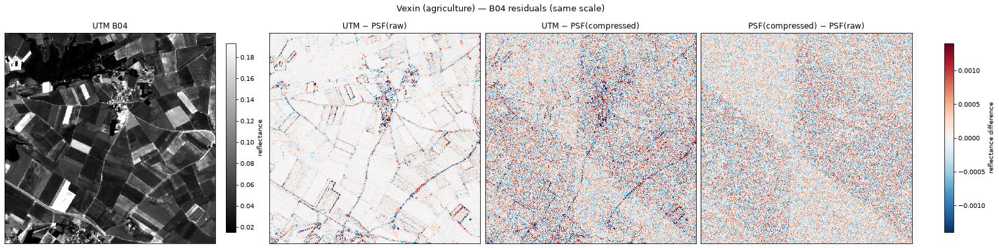

In [7]:
k = BANDS.index("b04")
for P in patches:
    imgs = [P["utm"][k] - P["psf"]["raw"][k], P["utm"][k] - P["psf"]["codec"][k],
            P["psf"]["codec"][k] - P["psf"]["raw"][k]]
    lim = np.nanpercentile(np.abs(imgs[1]), 99)
    fig, ax = plt.subplots(1, 4, figsize=(21, 5.4), constrained_layout=True)
    lo, hi = np.nanpercentile(P["utm"][k], [2, 98])
    h0 = ax[0].imshow(P["utm"][k], cmap="gray", vmin=lo, vmax=hi); ax[0].set_title("UTM B04")
    fig.colorbar(h0, ax=ax[0], shrink=0.8, label="reflectance")
    for a, im, t in zip(ax[1:], imgs, ["UTM − PSF(raw)", "UTM − PSF(compressed)", "PSF(compressed) − PSF(raw)"]):
        h = a.imshow(im, cmap="RdBu_r", vmin=-lim, vmax=lim); a.set_title(t)
    fig.colorbar(h, ax=ax[1:], shrink=0.8, label="reflectance difference")
    for a in ax:
        a.set_xticks([]); a.set_yticks([])
    fig.suptitle(f"{P['name']} — B04 residuals (same scale)", fontsize=13)
    plt.show()

## 6. Power spectra of the residuals

2D power spectral density (Hann window, mean removed), averaged over rings of radial spatial frequency. Normalisation: the integral of the 2D PSD over the frequency plane equals the variance of the field, so the curves are in reflectance²·km². The top axis gives the wavelength. The UTM Nyquist frequency is 50 cycles/km (10 m pixels), marked by the dotted line.

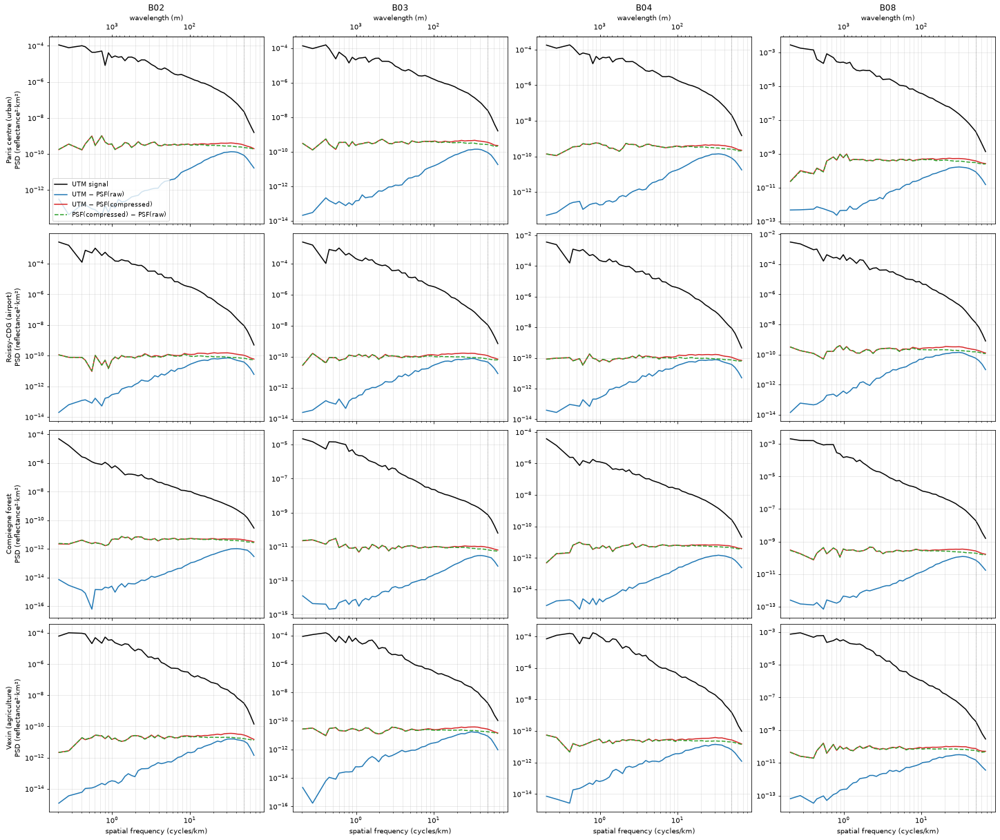

In [8]:
def radial_psd(img, dx=DX, nbins=60):
    a = np.array(img, float)
    a = np.where(np.isnan(a), np.nanmean(a), a)
    a -= a.mean()
    n = a.shape[0]
    w = np.outer(np.hanning(n), np.hanning(n))
    F = np.fft.fft2(a * w)
    psd2 = np.abs(F) ** 2 * dx * dx / (n * n * np.mean(w ** 2))        # refl² · m²
    f = np.fft.fftfreq(n, d=dx) * 1e3                                   # cycles/km
    kr = np.hypot(*np.meshgrid(f, f))
    edges = np.logspace(np.log10(1e3 / (n * dx)), np.log10(kr.max()), nbins + 1)
    idx = np.digitize(kr.ravel(), edges)
    p = np.bincount(idx, psd2.ravel(), minlength=nbins + 2)[1:nbins + 1]
    c = np.bincount(idx, minlength=nbins + 2)[1:nbins + 1]
    kc = np.sqrt(edges[1:] * edges[:-1])
    ok = c > 0
    return kc[ok], p[ok] / c[ok] / 1e6                                  # refl² · km²

CURVES = [("UTM signal", lambda P, i: P["utm"][i], "k", "-"),
          ("UTM − PSF(raw)", lambda P, i: P["utm"][i] - P["psf"]["raw"][i], "C0", "-"),
          ("UTM − PSF(compressed)", lambda P, i: P["utm"][i] - P["psf"]["codec"][i], "C3", "-"),
          ("PSF(compressed) − PSF(raw)", lambda P, i: P["psf"]["codec"][i] - P["psf"]["raw"][i], "C2", "--")]

fig, ax = plt.subplots(len(patches), len(BANDS), figsize=(20, 4.2 * len(patches)), sharex=True,
                       constrained_layout=True)
for r, P in enumerate(patches):
    for c, b in enumerate(BANDS):
        a = ax[r, c]
        for lab, fn, col, ls in CURVES:
            kx, p = radial_psd(fn(P, c))
            a.loglog(kx, p, color=col, ls=ls, label=lab)
        a.axvline(50, color="gray", lw=0.8, ls=":")
        a.grid(True, which="both", alpha=0.3)
        if r == 0:
            a.set_title(b.upper())
            sec = a.secondary_xaxis("top", functions=(lambda k: 1e3 / np.maximum(k, 1e-9), lambda l: 1e3 / np.maximum(l, 1e-9)))
            sec.set_xlabel("wavelength (m)")
        if c == 0:
            a.set_ylabel(f"{P['name']}\nPSD (reflectance²·km²)")
        if r == len(patches) - 1:
            a.set_xlabel("spatial frequency (cycles/km)")
ax[0, 0].legend(fontsize=9, loc="lower left")
plt.show()

### Spectral ratio

Ratio `PSD(UTM − PSF(compressed)) / PSD(UTM − PSF(raw))` per band for the 4 patches, on a logarithmic scale. A ratio close to 1 means that the codec adds almost nothing to the round-trip residual at that scale. A large ratio means that the codec error dominates the residual.

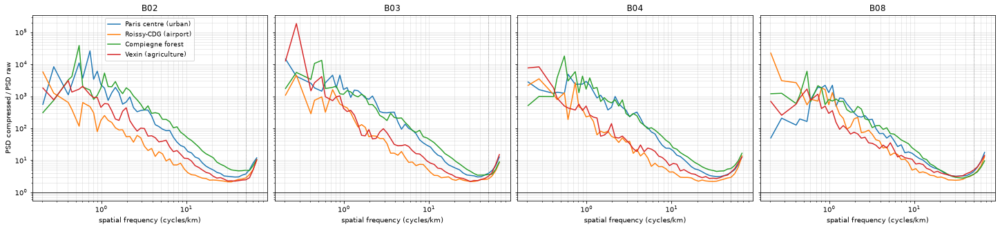

In [9]:
fig, ax = plt.subplots(1, len(BANDS), figsize=(20, 4.5), sharey=True, constrained_layout=True)
for c, b in enumerate(BANDS):
    for P in patches:
        k1, p_raw = radial_psd(P["utm"][c] - P["psf"]["raw"][c])
        _, p_cod = radial_psd(P["utm"][c] - P["psf"]["codec"][c])
        ax[c].loglog(k1, p_cod / p_raw, label=P["name"])
    ax[c].axhline(1, color="k", lw=0.8); ax[c].axvline(50, color="gray", lw=0.8, ls=":")
    ax[c].set_title(b.upper()); ax[c].set_xlabel("spatial frequency (cycles/km)"); ax[c].grid(True, which="both", alpha=0.3)
ax[0].set_ylabel("PSD compressed / PSD raw"); ax[0].legend(fontsize=9)
plt.show()